In [12]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pickle
import os
from scipy.sparse.linalg import svds
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import silhouette_score, pairwise_distances,davies_bouldin_score,calinski_harabasz_score
import math
import random
from PIL import Image
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from GMM_model import GMM
from KMeans_Robusto import KMeans_Robusto

In [2]:
train_df = pd.read_csv("data/train_features.csv")

X = train_df.drop(columns=["imdbId"]).values


In [3]:
class PCA_manual():
    def __init__(self, n_components):
        self.n_components = n_components
        self.mean_ = None
        self.components_ = None
        self.explained_variance_ = None

    def fit(self, X):
        # Centrar los datos
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Calcular SVD truncado
        U, S, Vt = svds(X_centered, k=self.n_components)

        # Seleccionar n_components
        self.components_ = Vt[:self.n_components, :]

        # Varianza explicada
        self.explained_variance_ = (S[:self.n_components] ** 2) / (X.shape[0] - 1)

        return self

    def transform(self, X):
        # Aplicar la transformación PCA usando los componentes entrenados
        if self.mean_ is None or self.components_ is None:
            raise ValueError("Primero debes llamar a fit() antes de transform().")
        X_centered = X - self.mean_
        X_pca = np.dot(X_centered, self.components_.T)
        return X_pca

    def fit_transform(self, X):
        # Entrenar y aplicar transformación en una sola llamada
        self.fit(X)
        return self.transform(X)

    def save(self, path):
        # Guardar el modelo entrenado en un archivo .pkl
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump({
                "n_components": self.n_components,
                "mean_": self.mean_,
                "components_": self.components_,
                "explained_variance_": self.explained_variance_
            }, f)

    @staticmethod
    def load(path):
        # Cargar un modelo PCA previamente guardado
        with open(path, "rb") as f:
            data = pickle.load(f)
        obj = PCA_manual(data["n_components"])
        obj.mean_ = data["mean_"]
        obj.components_ = data["components_"]
        obj.explained_variance_ = data["explained_variance_"]
        return obj

In [4]:
class UMAP_manual_L1:
    def __init__(self, n_neighbors=15, n_components=20, n_epochs=50, learning_rate=1.0, random_state=42):
        self.n_neighbors = n_neighbors
        self.n_components = n_components
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.random_state = random_state
        self.indices_ = None
        self.weights_ = None
        self.embedding_ = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples = X.shape[0]

        # k-vecinos más cercanos con distancia Manhattan ---
        nbrs = NearestNeighbors(n_neighbors=self.n_neighbors, metric='manhattan').fit(X)
        distances, indices = nbrs.kneighbors(X)

        # Convertir distancias a pesos (kernel exponencial) ---
        sigma = np.mean(distances[:, -1])
        weights = np.exp(-distances / (2 * sigma))   # usar distancia L1, sin elevar al cuadrado

        # Inicialización aleatoria ---
        X_UMAP = np.random.randn(n_samples, self.n_components) * 0.01

        # Optimización vectorizada ---
        for epoch in range(self.n_epochs):
            for i in range(n_samples):
                neighbors = indices[i]
                diffs = X_UMAP[i] - X_UMAP[neighbors]          # (n_neighbors, n_components)
                
                # Distancia Manhattan entre embeddings
                dists = np.sum(np.abs(diffs), axis=1, keepdims=True) + 1e-8

                # Gradiente según distancia L1
                direction = np.sign(diffs)                     # dirección del gradiente (signo)
                w = weights[i][:, None]
                grads = w * direction / (1 + dists)            # gradiente suavizado

                # Actualización
                X_UMAP[i] -= self.learning_rate * np.sum(grads, axis=0)
                X_UMAP[neighbors] += self.learning_rate * grads

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch + 1}/{self.n_epochs} completada")

        self.embedding_ = X_UMAP
        self.indices_ = indices
        self.weights_ = weights
        return self

    def transform(self, X):
        if self.embedding_ is None:
            raise ValueError("Primero debes llamar a fit() antes de transform().")
        nbrs = NearestNeighbors(n_neighbors=self.n_neighbors, metric='manhattan').fit(X)
        distances, indices = nbrs.kneighbors(X)
        sigma = np.mean(distances[:, -1])
        weights = np.exp(-distances / (2 * sigma))
        X_new = np.random.randn(X.shape[0], self.n_components) * 0.01
        for epoch in range(10):
            for i in range(X.shape[0]):
                neighbors = indices[i]
                diffs = X_new[i] - self.embedding_[neighbors]
                dists = np.sum(np.abs(diffs), axis=1, keepdims=True) + 1e-8
                direction = np.sign(diffs)
                w = weights[i][:, None]
                grads = w * direction / (1 + dists)
                X_new[i] -= self.learning_rate * np.sum(grads, axis=0)
                X_new[neighbors] += self.learning_rate * grads
        return X_new

    def fit_transform(self, X):
        self.fit(X)
        return self.embedding_

    def save(self, path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump({
                "n_neighbors": self.n_neighbors,
                "n_components": self.n_components,
                "n_epochs": self.n_epochs,
                "learning_rate": self.learning_rate,
                "random_state": self.random_state,
                "embedding_": self.embedding_,
                "indices_": self.indices_,
                "weights_": self.weights_
            }, f)

    @staticmethod
    def load(path):
        with open(path, "rb") as f:
            data = pickle.load(f)
        obj = UMAP_manual_L1(
            n_neighbors=data["n_neighbors"],
            n_components=data["n_components"],
            n_epochs=data["n_epochs"],
            learning_rate=data["learning_rate"],
            random_state=data["random_state"]
        )
        obj.embedding_ = data["embedding_"]
        obj.indices_ = data["indices_"]
        obj.weights_ = data["weights_"]
        return obj

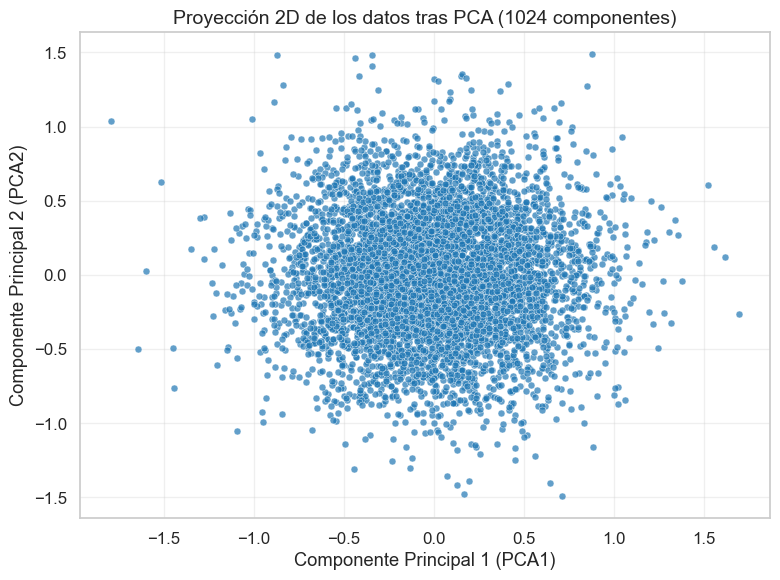

In [5]:
n_comp = 512
pca_model = PCA_manual(n_components=n_comp)
X_pca = pca_model.fit_transform(X)
df_pca = pd.DataFrame(X_pca, columns=[f"PCA{i+1}" for i in range(n_comp)])

# Graficando
plt.figure(figsize=(8,6))
sns.set(style="whitegrid", font_scale=1.1)
sns.scatterplot(
    data=df_pca,
    x="PCA1",
    y="PCA2",
    s=25,
    alpha=0.7,
    color="#1f77b4"
)

plt.title("Proyección 2D de los datos tras PCA (1024 componentes)", fontsize=14)
plt.xlabel("Componente Principal 1 (PCA1)")
plt.ylabel("Componente Principal 2 (PCA2)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Epoch 10/100 completada
Epoch 20/100 completada
Epoch 30/100 completada
Epoch 40/100 completada
Epoch 50/100 completada
Epoch 60/100 completada
Epoch 70/100 completada
Epoch 80/100 completada
Epoch 90/100 completada
Epoch 100/100 completada


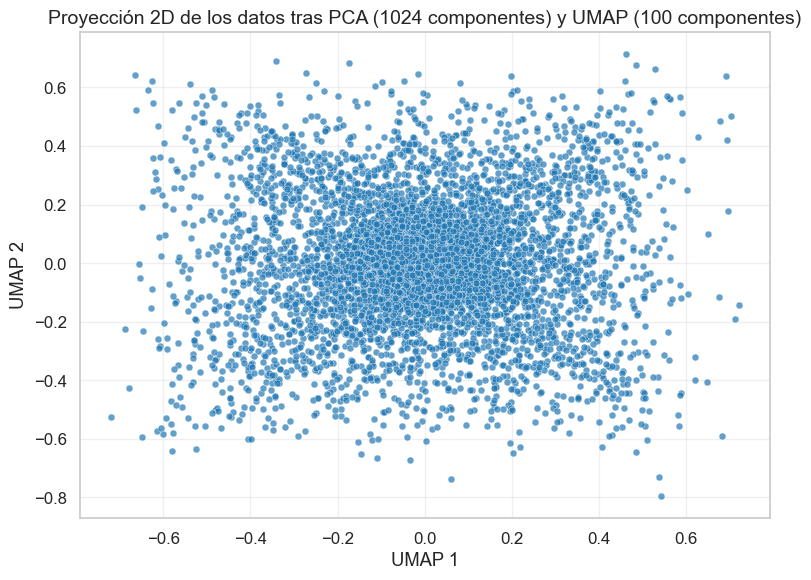

In [9]:
n_comp_UMAP = 100 
n_comp_PCA = 1024

pca_model = PCA_manual(n_components=n_comp_PCA)
X_pca = pca_model.fit_transform(X)
df_pca2 = pd.DataFrame(X_pca, columns=[f"PCA{i+1}" for i in range(n_comp_PCA)])

umap_model = UMAP_manual_L1(n_neighbors=15,n_components=n_comp_UMAP,
            n_epochs=100,learning_rate=1.0,random_state=42)
X_UMAP = umap_model.fit_transform(df_pca2)
df_UMAP = pd.DataFrame(X_UMAP, columns=[f"UMAP{i+1}" for i in range(n_comp_UMAP)])

# Graficando
plt.figure(figsize=(8,6))
sns.set(style="whitegrid", font_scale=1.1)
sns.scatterplot(
    data=df_UMAP,
    x="UMAP1",
    y="UMAP2",
    s=25,
    alpha=0.7,
    color="#1f77b4"
)

plt.title("Proyección 2D de los datos tras PCA (1024 componentes) y UMAP (100 componentes)", fontsize=14)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Dataset cargado: (6592, 2)
Shape de X (solo features): (6334, 34632)

 MÉTRICAS DE CLUSTERING:
→ Silhouette Score:          0.1954  (más alto = mejor, max=1)
→ Davies-Bouldin Index:      1.0939  (más bajo = mejor)
→ Calinski-Harabasz Score:   2126.1529  (más alto = mejor)


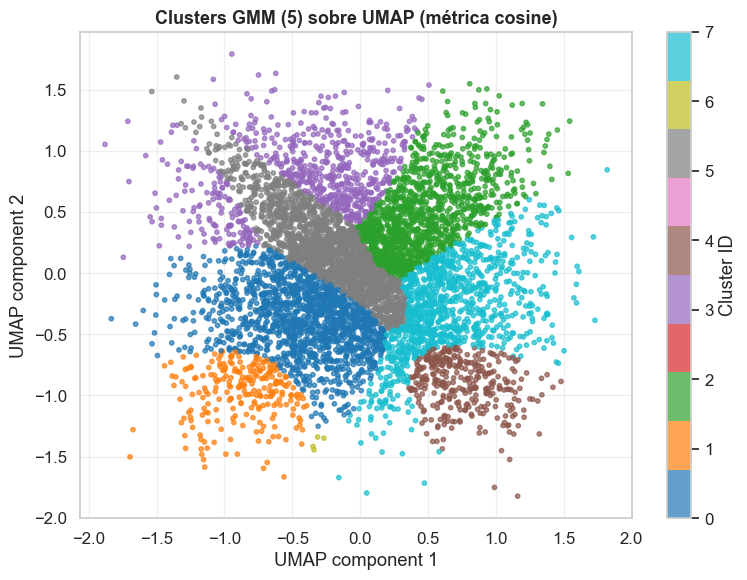

In [10]:
# ==========================================================
# 1. CARGAR FEATURES DESDE TU FOLDER
# ==========================================================
data_path = "data/features_reduced_UMAP_L1.csv"
df = pd.read_csv(data_path)
print(f"Dataset cargado: {df.shape}")

X_2 = df.values

print(f"Shape de X (solo features): {X.shape}")

# ==========================================================
# 4. ENTRENAR TU MODELO GMM PERSONALIZADO
# ==========================================================
gmm = GMM(n_components=8, max_iter=200, tol=1e-4, random_state=42)
gmm.fit(X_2)

# 🔸 Predecir etiquetas de cluster
R = gmm.E_step(X_2)
labels = np.argmax(R, axis=1)

# ==========================================================
# 5. MÉTRICAS DE EVALUACIÓN
# ==========================================================
silhouette = silhouette_score(X_2, labels)
davies_bouldin = davies_bouldin_score(X_2, labels)
calinski_harabasz = calinski_harabasz_score(X_2, labels)

print("\n MÉTRICAS DE CLUSTERING:")
print(f"→ Silhouette Score:          {silhouette:.4f}  (más alto = mejor, max=1)")
print(f"→ Davies-Bouldin Index:      {davies_bouldin:.4f}  (más bajo = mejor)")
print(f"→ Calinski-Harabasz Score:   {calinski_harabasz:.4f}  (más alto = mejor)")

# ==========================================================
# 6. VISUALIZAR RESULTADOS
# ==========================================================
plt.figure(figsize=(8, 6))
plt.scatter(X_2[:, 0], X_2[:, 1], c=labels, cmap='tab10', s=10, alpha=0.7)
plt.title("Clusters GMM (5) sobre UMAP (métrica cosine)", fontsize=13, fontweight='bold')
plt.xlabel("UMAP component 1")
plt.ylabel("UMAP component 2")
plt.colorbar(label="Cluster ID")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Resultados para K=20:
  ▸ Silhouette Score       = 0.112
  ▸ Davies-Bouldin Index   = 3.451
  ▸ Calinski-Harabasz Score= 12.462


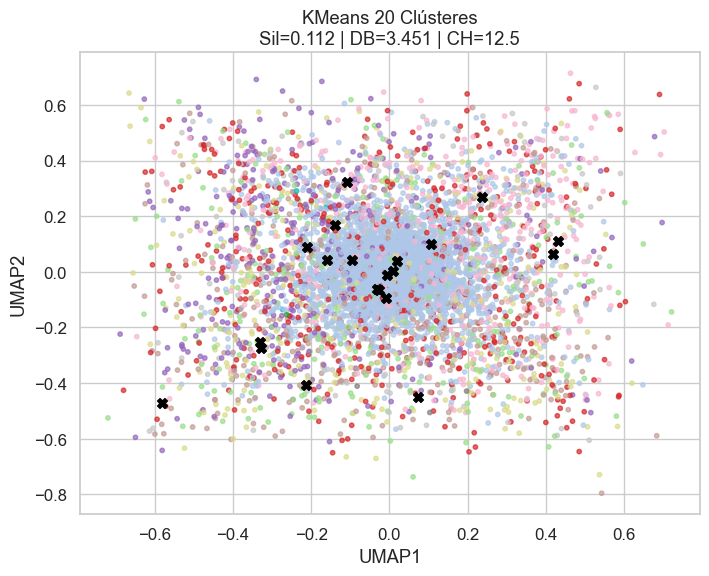

In [14]:

# Suponiendo que ya tienes tu clase KMeans_Robusto definida
# from tu_modulo import KMeans_Robusto  

def kmeans_umap_20_nosave(df_umap, random_state=42):
    X = df_umap.values if isinstance(df_umap, pd.DataFrame) else df_umap

    K = 20
    model = KMeans_Robusto(n_clusters=K, max_iter=500, n_init=5, random_state=random_state)
    model.fit(X)
    labels = model.labels_

    # Métricas de validación
    if len(np.unique(labels)) > 1:
        sil_score = silhouette_score(X, labels)
        db_index = davies_bouldin_score(X, labels)
        ch_score = calinski_harabasz_score(X, labels)
    else:
        sil_score = np.nan
        db_index = np.nan
        ch_score = np.nan

    print(f"Resultados para K={K}:")
    print(f"  ▸ Silhouette Score       = {sil_score:.3f}")
    print(f"  ▸ Davies-Bouldin Index   = {db_index:.3f}")
    print(f"  ▸ Calinski-Harabasz Score= {ch_score:.3f}")

    # Gráfico
    plt.figure(figsize=(8,6))
    plt.scatter(X[:,0], X[:,1], c=labels, s=10, cmap="tab20", alpha=0.7)
    plt.scatter(model.centroids[:,0], model.centroids[:,1], c="black", s=50, marker="X")
    plt.title(f"KMeans 20 Clústeres\nSil={sil_score:.3f} | DB={db_index:.3f} | CH={ch_score:.1f}")
    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")
    plt.show()

    return labels, sil_score, db_index, ch_score

# Uso
labels, sil_score, db_index, ch_score = kmeans_umap_20_nosave(df_UMAP)
